<h1 style="display:flex; align-items:center; line-height:1; margin:0;">
  <img src="rwcircle.png" style="height:36px; width:36px; border-radius:50%; flex-shrink:0;">
  <span style="padding-top:2px; margin-left:10px;"><b>A primer on Rocky Worlds DDT High Level Science Products (HLSPs)</b></span>
</h1>

***
**Author**: Nestor Espinoza (nespinoza@stsci.edu) | **Date of last change**: November 2026

## Summary
In this notebook, we take a look at the HLSPs coming out of the Rocky Worlds DDT. The objective of this notebook is to give a little "tour" through the possible HLSPs available as part of the Rocky Worlds DDT. It also sets the stage for you to be able to solve the school's challenge: plotting JWST/MIRI lightcurves of LHS 1140 together with HST/COS ones. 

## Pre-study imports and definitions
First, let's load useful libraries for this notebook:

In [24]:
# Generic python libraries:
import numpy as np
import matplotlib.pyplot as plt

# Some fits reading and time routines from astropy:
from astropy.io import fits
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation
import astropy.units as u

# Import h5py, which we will use to open h5 files:
import h5py

# This is a little of my own personal taste for plotting:
import seaborn as sns

# Import Observations to retrieve HLSPs (and observations too!):
from astroquery.mast import Observations

Next, we'll define some plotting standards --- this is, of course, personal preference!

In [2]:
# One of my favorite seaborn styles for plots:
sns.set_style('ticks')

# Also personal taste on plotting dimensions, etc.:
plt.rcParams.update({
    'figure.figsize': (10, 4),
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
})

We finally setup a flag in case this notebook wishes to be ran offline --- here "offline" meaning without querying from MAST (e.g., in case queries are too slow). To this end, we have stored some pre-downloaded HLSPs on November 2026 in this repository (note at the time you run this notebook, higher versions of the HLSPs might be available):

In [3]:
run_offline = False

# 1. Exploring Rocky Worlds DDT HLSPs

## 1.1 Exploring Rocky Worlds observations with available HLSPs

The easiest way of exploring observations that hold HLSPs from Rocky Worlds is simply doing a query as follows:

In [4]:
if not run_offline:

    all_observations = Observations.query_criteria(provenance_name="rocky-worlds")
    display( all_observations )

RemoteServiceError: Request failed.  If this problem persists, please notify archive[at]stsci.edu.'

This gets us a table with observations containing HLSPs. Let's print it --- because there are many columns on these tables, we'll select a few of the most important ones:

In [4]:
if not run_offline:

    columns = [
        'target_name',
        'obs_id',
        'project',
        'filters',
        'instrument_name',
        'dataproduct_type',
        't_min',
        't_max',
        't_exptime'
    ]
    
    display( all_observations[columns] )

target_name,obs_id,project,filters,instrument_name,dataproduct_type,t_min,t_max,t_exptime
str11,str55,str4,str35,str13,str10,float64,float64,float64
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl001_f1500w,JWST,F1500W,MIRI,timeseries,60864.3343153907,60864.55829641027,19352.928
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl002_f1500w,JWST,F1500W,MIRI,timeseries,60887.82100858686,60888.076465705664,22072.754
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl003_f1500w,JWST,F1500W,MIRI,timeseries,61070.95763864056,61071.21497740475,22232.744
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl004_f1500w,JWST,F1500W,MIRI,timeseries,61081.374564193415,61081.57165190959,17027.363
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-checkpoint02_f1500w,JWST,F1500W,MIRI,timeseries,60864.3343153907,61081.57165190959,80685.789
TOI-771 b,hlsp_rocky-worlds_jwst_miri_toi-771b-ecl001_f1500w,JWST,F1500W,MIRI,timeseries,61196.69655304606,61196.89523331626,17166.29
TOI-771 b,hlsp_rocky-worlds_jwst_miri_toi-771b-ecl003_f1500w,JWST,F1500W,MIRI,timeseries,61212.96978564273,61213.176876266574,17893.125
TOI-771 b,hlsp_rocky-worlds_jwst_miri_toi-771b-ecl002_f1500w,JWST,F1500W,MIRI,timeseries,61203.6992813629,61203.898361374384,17200.901
LTT 1445A,hlsp_rocky-worlds_hst_stis_ltt1445a_multi,HST,G230L;G750L,STIS,spectrum,61222.35607158,61222.37819533,1535.198625


This is a lot of information! Very likely you might be interested either on data from a single mission or from a single target. Both are easy to select from the tables above. For instance, suppose you only wanted data for GJ 3929 b:

In [13]:
if not run_offline:

    display( all_observations[ all_observations['target_name'] == 'GJ 3929 b' ][columns] )

target_name,obs_id,project,filters,instrument_name,dataproduct_type,t_min,t_max,t_exptime
str11,str55,str4,str35,str13,str10,float64,float64,float64
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl001_f1500w,JWST,F1500W,MIRI,timeseries,60864.3343153907,60864.55829641027,19352.928
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl002_f1500w,JWST,F1500W,MIRI,timeseries,60887.82100858686,60888.076465705664,22072.754
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl003_f1500w,JWST,F1500W,MIRI,timeseries,61070.95763864056,61071.21497740475,22232.744
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-ecl004_f1500w,JWST,F1500W,MIRI,timeseries,61081.374564193415,61081.57165190959,17027.363
GJ 3929 b,hlsp_rocky-worlds_jwst_miri_gj3929b-checkpoint02_f1500w,JWST,F1500W,MIRI,timeseries,60864.3343153907,61081.57165190959,80685.789


Neat! Note there are, in this case for JWST:

1. **Individual HLSPs for each targetted eclipse** with JWST, and,
2. **a "Checkpoint 2" JWST data product** --- one that contains results from an analysis made jointly to all eclipses.

Those same JWST HLSPs are expected to be released for every Rocky Worlds DDT target. The Checkpoint 2 data products are only produced once all the targetted observations are obtained and studied for a given target (marking the target as "done" from a perspective of the Rocky Worlds DDT's main observing strategy).

<div style="background-color: #edf5ff; border-left: 4px solid #3678c8; padding: 12px 16px; border-radius: 5px; margin: 12px 0;">
    💡 <strong>Note — Target naming conventions</strong>
    <p style="margin: 6px 0 0;">
    Target names on these observation tables (i.e., <code>target_name</code>) differ depending on whether you're referring to the
    star (<code>GJ 3929</code>) or planet (<code>GJ 3929 b</code>).
    </p>
</div>

What about stellar monitoring observations?

In [7]:
if not run_offline:
    
    all_observations[ all_observations['target_name'] == 'GJ 3929' ][columns]

target_name,obs_id,project,filters,instrument_name,dataproduct_type,t_min,t_max,t_exptime
str11,str55,str4,str35,str13,str10,float64,float64,float64
GJ 3929,hlsp_rocky-worlds_hst_cos-stis_gj3929_multi,HST,G130M;G140M;G160M;G230L;G430L;G750L,COS | STIS,spectrum,60872.21888377,61103.3061253,77719.17387500001


## 1.2 An alternative: exploring products in the HLSP MAST webpage

An even easier way to explore HLSPs is to visit the Rocky Worlds DDT HLSP MAST webpage: https://archive.stsci.edu/hlsp/rocky-worlds.

The webpage allows to download HLSPs in one click. Here, we have downloaded the eclipse 1 lightcurve `h5` data product for GJ 3929 b in this repository's `offline_data` folder. Let's load it:

In [5]:
jwst_lc1 = h5py.File('offline_data/part1/JWST/hlsp_rocky-worlds_jwst_miri_gj3929b-ecl001_f1500w_v1.0.1_lc.h5', 'r')

Note a lot of information lives in this lightcurve data product!

In [7]:
jwst_lc1.keys()

<KeysViewHDF5 ['rawFlux', 'rawFluxErr', 'astroModel', 'noiseModel', 'fullModel', 'cleanedFlux', 'centroid_x', 'centroid_y', 'centroid_sx', 'centroid_sy', 'visit', 'time', 'SRC_DOI', 'VISIT_ID', 'FILE_ID', 'MJD_BEG', 'MJD_MID', 'MJD_END', 'XPOSURE', 'CAL_VER', 'CRDS_VER', 'CRDS_CTX', 'PIPELINE', 'PIPE_VER', 'filter', 'subarray', 'date_obs', 'R_CAMERA', 'R_COLLIM', 'R_DARK', 'R_DISPER', 'R_DISTOR', 'R_MIREMI', 'R_FILOFF', 'R_FLAT', 'R_DFLAT', 'R_FFLAT', 'R_SFLAT', 'R_FORE', 'R_FPA', 'R_GAIN', 'R_IFUFOR', 'R_IFUPOS', 'R_IFUSLI', 'R_LINEAR', 'R_MASK', 'R_MSA', 'R_OTE', 'R_READNO', 'R_REGION', 'R_RESET', 'R_RSCD', 'R_SATURA', 'R_SPCWCS', 'R_WAVRAN', 'S_WCS', 'S_CHGMIG', 'S_CLNFNS', 'S_DARK', 'S_DQINIT', 'S_MIREMI', 'S_FRSTFR', 'S_FLAT', 'S_GANSCL', 'S_GRPSCL', 'S_IPC', 'S_JUMP', 'S_LASTFR', 'S_LINEAR', 'S_PHOTOM', 'S_RAMP', 'S_REFPIX', 'S_RESET', 'S_RSCD', 'S_SATURA']>

Of particular interest to this school's challenge are the `time`, `rawFlux` and `rawFluxErr` values. Note the `fullModel` is also included!

In [12]:
 jwst_lc1['time'][:], jwst_lc1['rawFlux'][:]

(array([2460864.8343426, 2460864.8344088, 2460864.8344749, ...,
        2460865.0581318, 2460865.058198 , 2460865.0582641], shape=(3387,)),
 array([[      nan,       nan,       nan, ..., 0.9972957, 0.9987239,
         0.9983109]], shape=(1, 3387)))

Text(0.5, 1.0, 'GJ 3929 b — JWST/MIRI Eclipse 1')

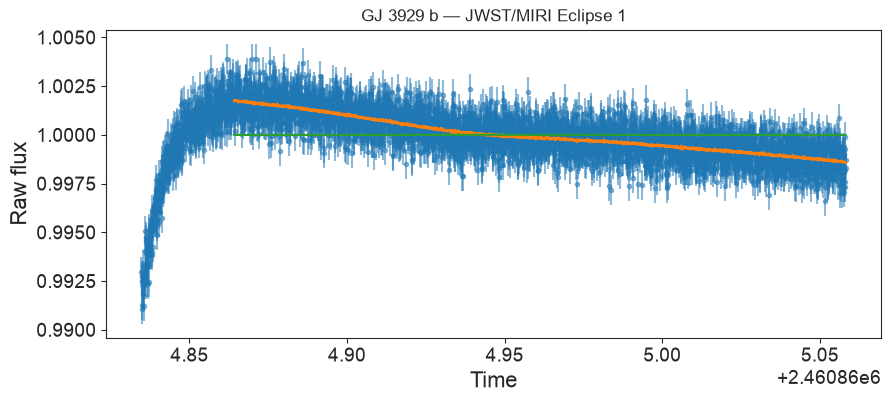

In [17]:
plt.errorbar(
    jwst_lc1['time'][:],
    jwst_lc1['rawFlux'][:][0,:],
    yerr=jwst_lc1['rawFluxErr'][:][0,:],
    fmt='.',
    alpha=0.5, 
    zorder = 0
)

plt.plot(

    jwst_lc1['time'][:],
    jwst_lc1['fullModel'][:][0,:],
    zorder = 1
    
)

plt.plot(

    jwst_lc1['time'][:],
    jwst_lc1['astroModel'][:][0,:],
    zorder = 1
    
)

plt.xlabel('Time')
plt.ylabel('Raw flux')
plt.title('GJ 3929 b — JWST/MIRI Eclipse 1')

We can do the very same with, e.g., HST/COS lightcurves. We've also stored one of them in the same folder --- let's load it:

In [18]:
visit1 = fits.open( 'offline_data/part1/HST/hlsp_rocky-worlds_hst_cos_gj3929-visit01_g130m_v1.0_lc.fits' )

Note the length of this array we've loaded is of dimension 3:

In [19]:
len(visit1)

3

This is because the first one holds all the high-level information, the second array holds the lightcurve from segments A (1230-1365 Angstroms) and B (1140-1214 Angstroms). Let's plot, e.g., the lightcurve for segment A:

In [28]:
visit1.info()

Filename: offline_data/part1/HST/hlsp_rocky-worlds_hst_cos_gj3929-visit01_g130m_v1.0_lc.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      28   ()      
  1                1 BinTableHDU     35   4R x 5C   ['485D', '485D', '485D', '485D', '485D']   
  2                1 BinTableHDU     35   4R x 5C   [485D, 485D, 485D, 485D, 485D]   


OK! Let's plot, e.g., the lightcurve for segment A. First, note the times are in MJD UTC:

In [20]:
visit1[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
HLSPTYPE= 'Light curve'        / HLSP Type                                      
DATE-BEG= '2026-01-30 21:10:37.832' / ISO-8601 date-time start of the observatio
DATE-END= '2026-01-31 02:16:53.960' / ISO-8601 date-time end of the observation 
DOI     = '10.17909/qsyr-ny68' / Digital Object Identifier                      
HLSPID  = 'ROCKY-WORLDS'       / Identifier of this HLSP collection             
HLSP_PI = 'Hannah Diamond-Lowe' / Principal Investigator of this HLSP collection
HLSPLEAD= 'Leonardo dos Santos' / Full name of HLSP project lead                
HLSPNAME= 'Rocky Worlds DDT'   / Title of this HLSP project                     
HLSPTARG= 'GJ-3929 '        

Also, note the dimension of the time axis for segment A's data:

In [21]:
visit1[1].data['TIME'].shape

(4, 485)

This is because there are 4 orbits of data, each with 485 time samples. Let's first write a simple function that gets timestamps from MJD to BJD (we'll assume HST is at Earth --- this adds a tiny offset that you might want to correct on real science applications, although its small --- of order a few tens of milliseconds):

In [22]:
def mjdutc_to_bjdtdb(visit):

    # Extract target coordinates:
    target = SkyCoord(
                        ra=visit.header['RA_TARG'] * u.deg,
                        dec=visit.header['DEC_TARG'] * u.deg
                     )

    # Simple target location on Earth:
    location = EarthLocation.from_geocentric(0, 0, 0, unit=u.m)

    # Input timestamps in the data product:
    output_times = np.zeros( visit.data['TIME'].shape )
    for i in range( visit.data['TIME'].shape[0] ):

            # Let's pre-mask nans from non-nans:
            idx_nan = np.isnan( visit.data['TIME'][i, :] ) 
            idx_NOT_nan = ~idx_nan
        
            # Get UTC time in astropy format:
            time_utc = Time(
                                visit.data['TIME'][i, :][idx_NOT_nan],
                                format='mjd',
                                scale='utc',
                                location=location
                           )

            # Light travel time correction:
            ltt = time_utc.light_travel_time(target, kind='barycentric')

            # Get BJD TDB:
            output_times[i, idx_NOT_nan] = (time_utc.tdb + ltt).jd
            output_times[i, idx_nan] = np.nan

    return output_times

Let's extract the relevant data:

In [25]:
# Visit 1 dataset, segment A:
visit1_timesA = mjdutc_to_bjdtdb(visit1[1])
visit1_fluxA = visit1[1].data['FLUX']
visit1_fluxerrA = visit1[1].data['FLUXERROR']

And plot!

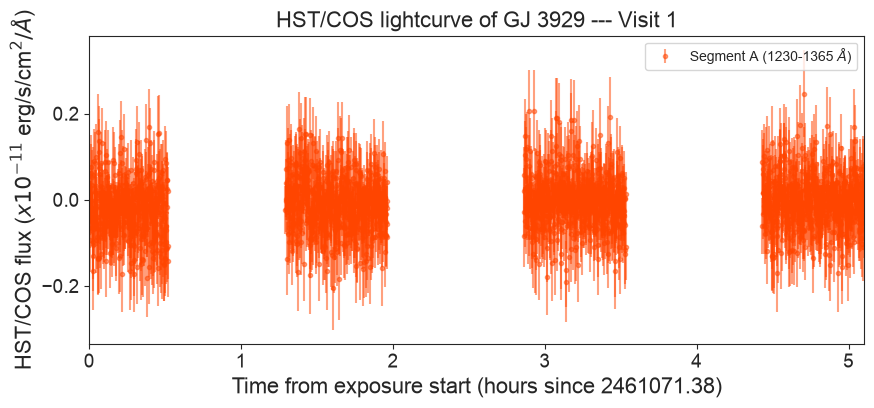

In [27]:
plt.title(r'HST/COS lightcurve of GJ 3929 --- Visit 1', fontsize=16)

min_time = np.nanmin(visit1_timesA)
set_legend = True
legendA = r'Segment A (1230-1365 $\AA$)'

for k in range(4):
        
    thoursA = ( visit1_timesA[k, :] - min_time ) * 24

    plt.errorbar(thoursA, visit1_fluxA [k, :]*1e11, visit1_fluxerrA[k, :]*1e11, fmt='.', color = 'orangered', alpha = 0.5, label = legendA)

    if set_legend:
           plt.legend()
           set_legend = False
           legendA = None
    
plt.xlabel('Time from exposure start (hours since {0:.2f})'.format(min_time))
plt.ylabel(r'HST/COS flux ($x 10^{-11}$ erg/s/cm$^{2}/\AA$)')

plt.xlim(np.nanmin(visit1_timesA[0,:] - min_time) * 24, np.nanmax(visit1_timesA[-1,:] - min_time) * 24)
plt.show()

Note it's easy to do the same for Segment B:

In [29]:
# Visit 1 dataset, segment A:
visit1_timesB = mjdutc_to_bjdtdb(visit1[2])
visit1_fluxB = visit1[2].data['FLUX']
visit1_fluxerrB = visit1[2].data['FLUXERROR']

In [ ]:
plt.title(r'HST/COS lightcurve of GJ 3929 --- Visit 1', fontsize=16)

min_time = np.nanmin(visit1_timesB)
set_legend = True
legendB = r'Segment B (1140-1214 $\AA$)'

for k in range(4):
        
    thoursB = ( visit1_timesB[k, :] - min_time ) * 24

    plt.errorbar(thoursB, visit1_fluxB [k, :]*1e11, visit1_fluxerrB[k, :]*1e11, fmt='.', color = 'c', alpha = 0.5, label = legendA)

    if set_legend:
           plt.legend()
           set_legend = False
           legendB = None
    
plt.xlabel('Time from exposure start (hours since {0:.2f})'.format(min_time))
plt.ylabel(r'HST/COS flux ($x 10^{-11}$ erg/s/cm$^{2}/\AA$)')

plt.xlim(np.nanmin(visit1_timesA[0,:] - min_time) * 24, np.nanmax(visit1_timesA[-1,:] - min_time) * 24)
plt.show()

# 2. The Challenge: Comparing Simultaneous JWST and HST Observations of LHS 1140

Now it's your turn! Using the Rocky Worlds DDT [HLSP products](https://archive.stsci.edu/hlsp/rocky-worlds), your challenge is to explore the simultaneous JWST and HST observations of the **LHS 1140** system.

1. **Retrieve and plot** the JWST/MIRI and HST/COS light curves of LHS 1140. Remember that COS has two detector segments (A and B)!
2. **Identify simultaneous observations.** Which JWST and HST visits overlap in time? Use the provided MJD-to-BJD conversion function if needed.
3. **Compare the light curves.** What similarities and differences do you notice between the JWST and HST observations?

**Bonus challenge:** Can you identify signatures of stellar flaring? How do these appear at different wavelengths, and what does this tell us about the importance of simultaneous observations?

*Hint: Focus on getting the observations onto a common time axis. You don't need to fit any models!*


***

<table style="width:100%; border:0;">
<tr>
<td style="text-align:left; vertical-align:middle;">
<a href="#top">Top of Page</a>
</td>

<td style="text-align:right; vertical-align:middle;">
<img src="https://raw.githubusercontent.com/spacetelescope/roman_notebooks/7f391657bc2bf47a784400d65d2882703787416d/stsci_logo2.png"
     alt="Space Telescope Logo"
     width="80px"/>
</td>
</tr>
</table>